# Predicting ETH Price Volatility from Donald Trump's Social-Media Posts

**Data Science Project — CRISP-DM workflow**

This notebook builds a **binary classification** model that predicts whether a **large ETH price move** (high volatility) follows one of Donald Trump's social-media posts.

We follow the standard data-science process (CRISP-DM):

1. **Business / Problem Understanding** — define the question and hypothesis
2. **Data Understanding** — the datasets and their properties
3. **Data Preparation** — cleaning, label creation, feature engineering, train/test split
4. **Exploratory Data Analysis (EDA)** — visual & statistical exploration
5. **Modeling** — baseline bake-off of several algorithms
6. **Evaluation** — metrics, confusion matrix, ROC curve, feature importance
7. **Improving the Model** — leakage-safe market-context features + stronger models
8. **Rigorous Validation** — walk-forward CV, threshold tuning, error analysis
9. **Conclusion** — findings, limitations, future work

## 1. Business / Problem Understanding

**Motivation.** Donald Trump is one of the most-followed political figures, and his posts frequently move financial markets. This project asks whether his posts carry any predictive information for the **Ethereum (ETH)** cryptocurrency market.

**Why volatility, not direction?** A preliminary experiment (predicting whether ETH goes *up or down* after a post) performed **at or below random chance (~49–50%)** across every configuration. This is consistent with the *Efficient Market Hypothesis*: the direction of short-term returns is essentially unpredictable from public text.

However, the **magnitude** of a move (volatility) is a different, more tractable target — important news tends to precede large price swings regardless of direction. We therefore reframe the task:

> **Problem:** Given a Trump post, classify whether the ETH price will experience a **BIG move** vs a **SMALL move** in the hour after the post.

**Hypothesis (H1):** Features derived from a post (text content, sentiment, engagement, topic keywords) contain signal that predicts near-term ETH volatility better than chance.

**Type of task:** Supervised **binary classification**. **Primary metric:** accuracy and ROC-AUC vs a majority-class baseline.

## 2. Data Understanding

Two data sources were collected (see `fetch_eth.py`, the Rust/Python scrapers, and `build_dataset.py`):

| Dataset | Source | Rows | Description |
|---|---|---|---|
| Trump posts | Truth Social + Twitter/X | ~96k | id, timestamp, text, likes, reposts, platform |
| ETH price | Binance ETH/USDT hourly | ~80k | hourly OHLC candles, Aug 2017 → 2026 |

`build_dataset.py` **joined** each post to the ETH candle of the hour it was posted, then computed the return over the next hour. The result is `csv/dataset.csv`, which we load below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

df = pd.read_csv('csv/dataset.csv')
print('shape:', df.shape)
df.head()

shape: (63039, 18)


,id,date,platform,text,eth_entry,eth_1h,eth_24h,ret_1h,ret_24h,label_1h,label_24h,word_count,favorite_count,repost_count,hour_utc,weekday,has_crypto_kw,has_econ_kw
0,117270538101466607,2026-09-14 17:20:04+00:00,Truth Social,"The $5,000 Trump Dividend, to be given to all ...",2533.37,2538.86,2441.21,0.00217,-0.03638,UP,DOWN,158,338,123,17,0,1,1
1,117270347763611160,2026-09-14 16:31:39+00:00,Truth Social,I hope everyone realizes that price increases ...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,88,4168,1204,16,0,0,0
2,117270324606038555,2026-09-14 16:25:46+00:00,Truth Social,Oil is flowing through the Hormuz Strait. The ...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,59,3798,1021,16,0,0,0
3,117270313550921566,2026-09-14 16:22:57+00:00,Truth Social,I’ve just received a Report that the United St...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,93,3606,938,16,0,0,1
4,117270114981057392,2026-09-14 15:32:27+00:00,Truth Social,The failing Nation of Iran wants to make a dea...,2508.48,2529.05,2424.46,0.00820,-0.03349,UP,DOWN,46,13257,2860,15,0,1,0


In [2]:
# Structure, dtypes and missing values
df.info()
print('\nMissing values per column:')
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 63039 entries, 0 to 63038
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              63039 non-null  int64  
 1   date            63039 non-null  str    
 2   platform        63039 non-null  str    
 3   text            60947 non-null  str    
 4   eth_entry       63039 non-null  float64
 5   eth_1h          63039 non-null  float64
 6   eth_24h         62972 non-null  float64
 7   ret_1h          63039 non-null  float64
 8   ret_24h         62972 non-null  float64
 9   label_1h        63039 non-null  str    
 10  label_24h       62972 non-null  str    
 11  word_count      63039 non-null  int64  
 12  favorite_count  63039 non-null  int64  
 13  repost_count    63039 non-null  int64  
 14  hour_utc        63039 non-null  int64  
 15  weekday         63039 non-null  int64  
 16  has_crypto_kw   63039 non-null  int64  
 17  has_econ_kw     63039 non-null  int64  
dt

In [3]:
# Descriptive statistics of the numeric columns
df[['ret_1h', 'ret_24h', 'word_count', 'favorite_count', 'repost_count']].describe()

,ret_1h,ret_24h,word_count,favorite_count,repost_count
count,63039.000000,62972.000000,63039.000000,6.303900e+04,63039.000000
mean,0.000091,0.001469,27.420628,3.347209e+04,8746.335982
std,0.008942,0.039251,38.676234,5.638955e+04,11577.010873
min,-0.208730,-0.396410,0.000000,0.000000e+00,0.000000
25%,-0.002950,-0.016380,3.000000,5.901000e+03,2269.000000
50%,0.000020,0.000870,17.000000,1.452700e+04,4760.000000
75%,0.003150,0.018910,37.000000,4.061100e+04,11573.000000
max,0.180790,0.381320,724.000000,1.905628e+06,398663.000000


**What the raw data shows.**

- **Returns are tiny but heavy-tailed.** The median 1-hour return is ≈0% and the inter-quartile range is only ±0.3%, yet the extremes reach **−21% to +18%**. Most hours are quiet; a few are violent. This long tail is exactly why *volatility* (magnitude), not *direction*, is the sensible target.
- **Engagement is extremely skewed.** The median post gets ~15k likes and ~4.8k reposts, but the maximum exceeds **1.9M likes**. Such skew means these features must be **standardized** (done in §5) before linear models can use them sensibly.
- **A little data is missing.** ~2,100 posts (3.3%) have no text — these are image- or link-only posts — and 67 rows lack a 24-hour return. We keep the text-less posts (their timing and engagement are still informative) and fill the empty text with `''`; the 1-hour return, our label source, is complete.

## 3. Data Preparation

Steps:
1. **Parse dates** and sort chronologically (needed for a time-based split).
2. **Create the target label**: `BIG` if the absolute 1-hour return `|ret_1h|` exceeds a threshold, else `SMALL`. We use the **median** of `|ret_1h|` as the threshold, which produces two balanced classes — a clean setup for classification.
3. **Feature engineering**: add a **sentiment** score (VADER compound) from the post text, plus the engagement / time / keyword features already present.
4. **Train/test split**: **time-based** (train on the oldest 80%, test on the most recent 20%) to avoid look-ahead leakage.

In [4]:
# 3.1 Parse dates, drop rows without a 1h return, sort chronologically
df['date'] = pd.to_datetime(df['date'], utc=True)
df = df.dropna(subset=['ret_1h']).sort_values('date').reset_index(drop=True)
df['abs_ret_1h'] = df['ret_1h'].abs()
print('rows after cleaning:', len(df))

rows after cleaning: 63039


In [5]:
# 3.2 Create the volatility target (median threshold -> balanced classes)
threshold = df['abs_ret_1h'].median()
df['target'] = (df['abs_ret_1h'] > threshold).astype(int)  # 1 = BIG move
print(f'Volatility threshold (median |ret_1h|): {threshold:.4f}  ({threshold*100:.2f}%)')
print(df['target'].value_counts(normalize=True).rename({0: 'SMALL', 1: 'BIG'}))

Volatility threshold (median |ret_1h|): 0.0031  (0.30%)
target
SMALL    0.500769
BIG      0.499231
Name: proportion, dtype: float64


In [6]:
# 3.3 Feature engineering: VADER sentiment on the post text (~1 min on 63k rows)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
df['text'] = df['text'].fillna('')
df['sentiment'] = df['text'].apply(lambda t: vader.polarity_scores(t)['compound'])
df['text_len'] = df['text'].str.len()
df[['text', 'sentiment']].head()

,text,sentiment
0,Publicity seeking Lindsey Graham falsely state...,-0.2500
1,...and people like Ms. Heyer. Such a disgustin...,-0.1346
2,The public is learning (even more so) how dish...,-0.9344
3,Great to see that Dr. Kelli Ward is running ag...,-0.5147
4,Many meetings today in Bedminster including wi...,0.6588


In [7]:
# 3.4 Time-based train/test split (no shuffling!)
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]
print(f'train: {len(train)} rows  ({train.date.min().date()} .. {train.date.max().date()})')
print(f'test : {len(test)} rows  ({test.date.min().date()} .. {test.date.max().date()})')

train: 50431 rows  (2017-08-17 .. 2025-01-03)
test : 12608 rows  (2025-01-03 .. 2026-09-14)


## 4. Exploratory Data Analysis (EDA)

We explore the distribution of the target and the relationships between features and volatility before modeling.

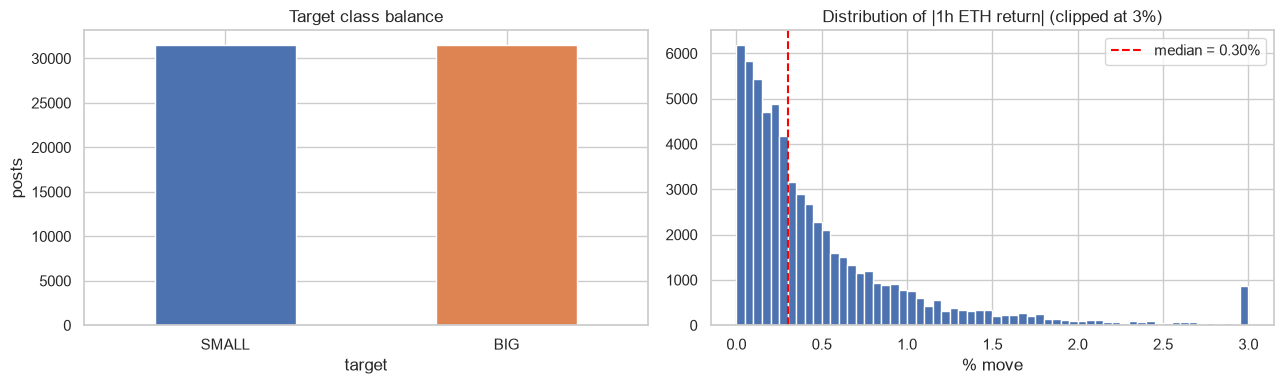

In [8]:
# 4.1 Target balance and the distribution of |1h return|
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['target'].map({0: 'SMALL', 1: 'BIG'}).value_counts().plot(kind='bar', ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Target class balance'); ax[0].set_ylabel('posts'); ax[0].tick_params(axis='x', rotation=0)
ax[1].hist(df['abs_ret_1h'].clip(upper=0.03) * 100, bins=60, color='#4C72B0')
ax[1].axvline(threshold * 100, color='red', ls='--', label=f'median = {threshold*100:.2f}%')
ax[1].set_title('Distribution of |1h ETH return| (clipped at 3%)'); ax[1].set_xlabel('% move'); ax[1].legend()
plt.tight_layout(); plt.show()

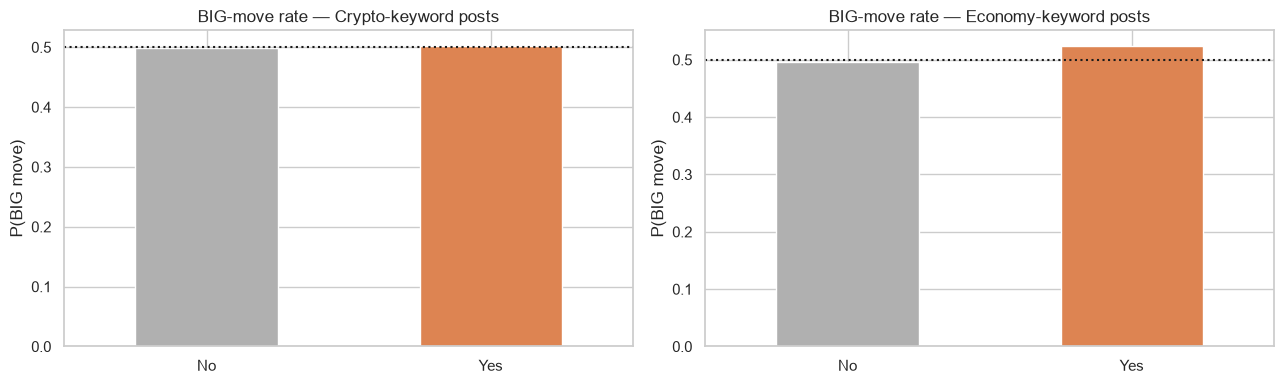

In [9]:
# 4.2 Does volatility differ for crypto/economy posts vs the rest?
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, a, title in [('has_crypto_kw', ax[0], 'Crypto-keyword posts'), ('has_econ_kw', ax[1], 'Economy-keyword posts')]:
    rates = df.groupby(col)['target'].mean()
    rates.index = ['No', 'Yes']
    rates.plot(kind='bar', ax=a, color=['#B0B0B0', '#DD8452'])
    a.set_title(f'BIG-move rate — {title}'); a.set_ylabel('P(BIG move)'); a.axhline(0.5, color='k', ls=':')
    a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

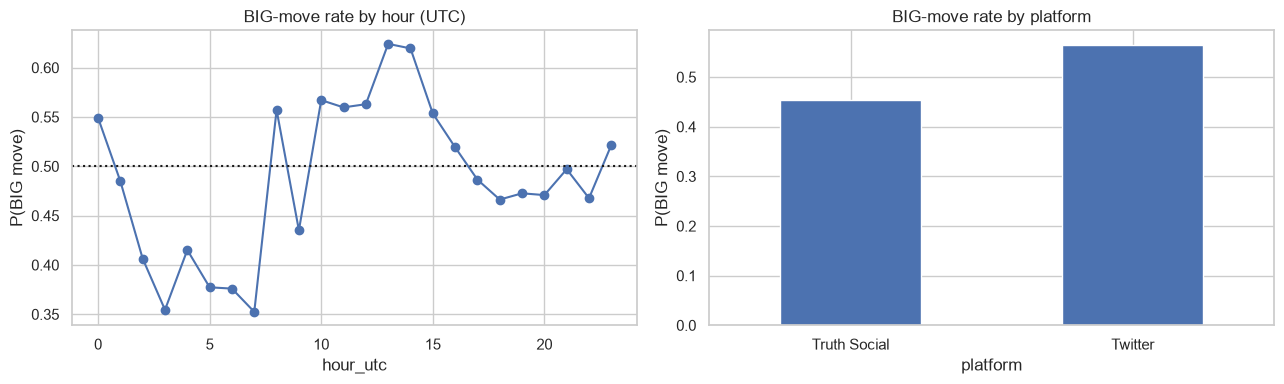

In [10]:
# 4.3 Volatility by hour of day and by platform
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby('hour_utc')['target'].mean().plot(ax=ax[0], marker='o')
ax[0].set_title('BIG-move rate by hour (UTC)'); ax[0].set_ylabel('P(BIG move)'); ax[0].axhline(0.5, color='k', ls=':')
df.groupby('platform')['target'].mean().plot(kind='bar', ax=ax[1], color='#4C72B0')
ax[1].set_title('BIG-move rate by platform'); ax[1].set_ylabel('P(BIG move)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

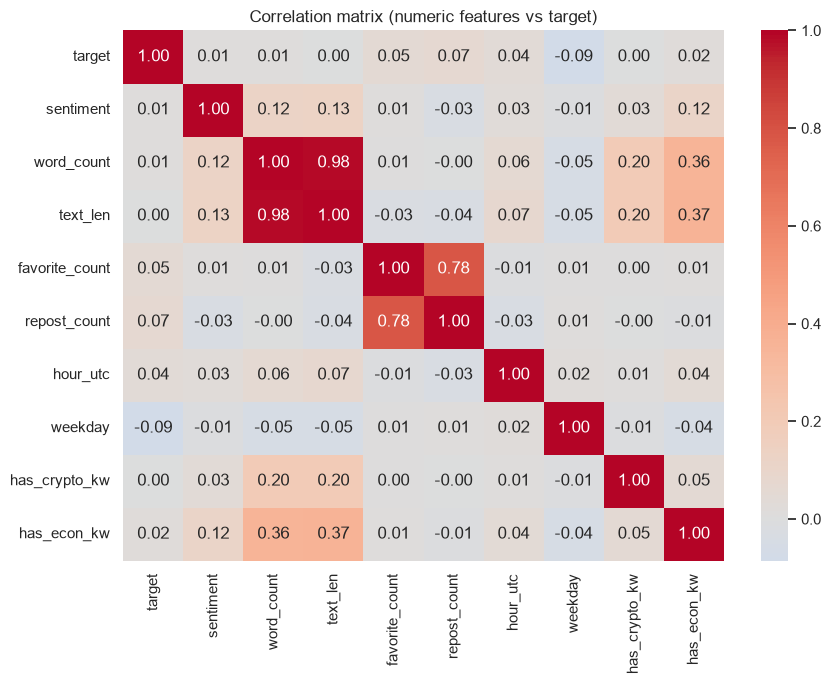

In [11]:
# 4.4 Correlation of numeric features with the target
num_cols = ['target', 'sentiment', 'word_count', 'text_len', 'favorite_count',
            'repost_count', 'hour_utc', 'weekday', 'has_crypto_kw', 'has_econ_kw']
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (numeric features vs target)'); plt.tight_layout(); plt.show()

### What the EDA tells us

- **The target is balanced (~50/50)** by construction, so plain accuracy is meaningful and the majority-class baseline sits at ≈0.50 — the number every model must beat.
- **Topic keywords barely move the needle.** Crypto-keyword posts have almost the same BIG-move rate as the rest (50.3% vs 49.1%); economy-keyword posts are only slightly higher (52.5% vs 49.6%). Hand-made keyword flags are weak signals on their own.
- **Platform shows the biggest gap — but it is confounded by time.** Twitter posts precede a BIG move 56.6% of the time vs 45.4% for Truth Social. This almost certainly reflects *era*, not platform: the Twitter posts are from 2017–2022 (a more volatile ETH regime), while Truth Social dominates 2023 onward. A caution against over-reading this feature.
- **Time of day matters a little.** The BIG-move rate ranges from ~35% (07:00 UTC, Asian off-hours) to ~62% (13:00 UTC, the US pre-market/open) — consistent with volatility tracking *active trading hours* rather than post content.
- **All linear correlations with the target are very weak** (|r| ≤ 0.09). The strongest are engagement (reposts r≈0.07, likes r≈0.05) and weekday (r≈−0.09, weekends calmer). No single feature is a strong predictor — any real signal must come from *combinations* of features, which motivates the multi-feature models below.

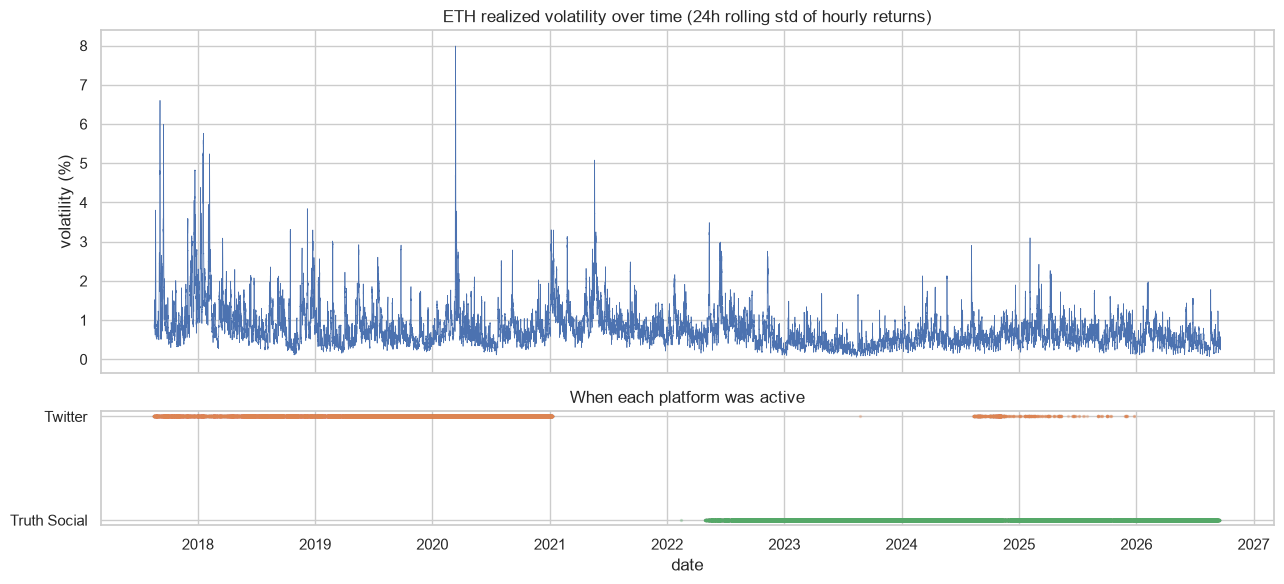

In [12]:
# 4.5 Volatility over time -- and why the "platform" gap is really an "era" gap
pxv = pd.read_csv('csv/eth_price.csv', parse_dates=['timestamp']).sort_values('timestamp')
pxv['rv_24h'] = pxv['close'].pct_change().rolling(24).std() * 100   # % hourly vol, 24h window

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                       gridspec_kw={'height_ratios': [3, 1]})
ax[0].plot(pxv['timestamp'], pxv['rv_24h'], lw=0.5, color='#4C72B0')
ax[0].set_title('ETH realized volatility over time (24h rolling std of hourly returns)')
ax[0].set_ylabel('volatility (%)')
for plat, y, color in [('Twitter', 1, '#DD8452'), ('Truth Social', 0, '#55A868')]:
    sub = df[df['platform'] == plat]
    ax[1].scatter(sub['date'], np.full(len(sub), y), s=2, color=color, alpha=0.25)
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(['Truth Social', 'Twitter'])
ax[1].set_title('When each platform was active'); ax[1].set_xlabel('date')
plt.tight_layout(); plt.show()


**Reading this chart.** Volatility is not constant — it comes in **regimes**: violent in 2018, 2020–21 and 2022, far calmer in 2023–24. Crucially, the two platforms occupy **different time windows** (Twitter ≈2017–2022, Truth Social ≈2022→now), so they overlap with *different* volatility regimes. This is direct visual proof that the "platform" effect from §4.3 is really a **time/era effect** — a confound we must not mistake for a property of the platform itself. It also previews §7's key idea: the ETH market's *own recent volatility* is highly informative about its near-future volatility.

## 5. Modeling

**Feature representation.** We combine two feature groups:
- **Text**: TF-IDF vectors of the post (unigrams + bigrams, top 2000 terms).
- **Numeric**: sentiment, engagement, time, and keyword flags (standardized).

**Algorithms compared** (a required part of the DS process — we benchmark several families):
1. **Dummy** (majority class) — the baseline every model must beat
2. **Logistic Regression** — linear model
3. **Linear SVM** — max-margin linear classifier
4. **Random Forest** — non-linear ensemble of trees

The TF-IDF vectorizer is **fit on the training set only** to prevent data leakage.

In [13]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

NUM = ['sentiment', 'word_count', 'text_len', 'favorite_count', 'repost_count',
       'hour_utc', 'weekday', 'has_crypto_kw', 'has_econ_kw']

# TF-IDF (fit on train only)
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5, stop_words='english')
Xtr_txt = tfidf.fit_transform(train['text'])
Xte_txt = tfidf.transform(test['text'])

# Standardize numeric features using TRAIN statistics only
mu, sd = train[NUM].mean(), train[NUM].std() + 1e-9
Xtr_num = csr_matrix((train[NUM] - mu) / sd)
Xte_num = csr_matrix((test[NUM] - mu) / sd)

X_train = hstack([Xtr_txt, Xtr_num]).tocsr()
X_test = hstack([Xte_txt, Xte_num]).tocsr()
y_train, y_test = train['target'].values, test['target'].values
print('feature matrix:', X_train.shape)

feature matrix: (50431, 2009)


In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def proba(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    s = model.decision_function(X)  # LinearSVC
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0),
    'Linear SVM': LinearSVC(C=0.5),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=20, n_jobs=-1, random_state=42),
}

rows = []
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    pred = m.predict(X_test)
    try:
        auc = roc_auc_score(y_test, proba(m, X_test))
    except Exception:
        auc = np.nan
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'roc_auc': auc})
results = pd.DataFrame(rows).set_index('model').round(4)
results

,accuracy,f1,roc_auc
model,,,
Dummy (majority),0.4996,0.0000,0.5000
Logistic Regression,0.5226,0.4498,0.5262
Linear SVM,0.5203,0.4493,0.5254
Random Forest,0.5423,0.3692,0.5708


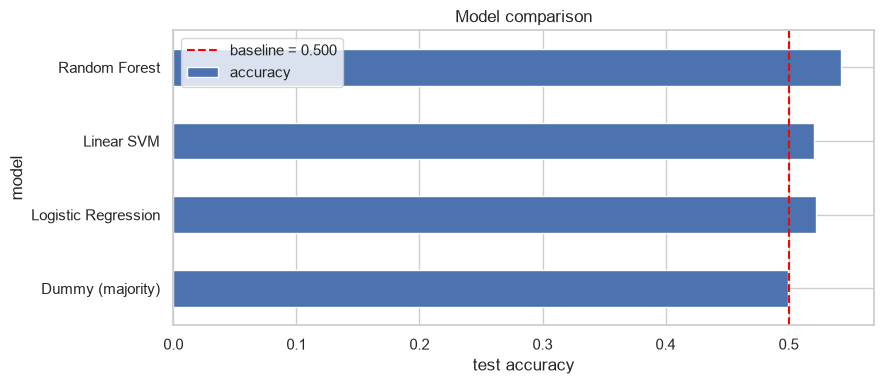

In [15]:
# Visual comparison of model accuracy vs the baseline
baseline = max(y_test.mean(), 1 - y_test.mean())
ax = results['accuracy'].plot(kind='barh', figsize=(9, 4), color='#4C72B0')
ax.axvline(baseline, color='red', ls='--', label=f'baseline = {baseline:.3f}')
ax.set_xlabel('test accuracy'); ax.set_title('Model comparison'); ax.legend(); plt.tight_layout(); plt.show()

### Reading the model comparison

- **Every model beats the majority baseline (0.50)** — but only modestly. Logistic Regression and Linear SVM reach ~0.52 accuracy; **Random Forest leads at 0.542 accuracy and 0.571 ROC-AUC**.
- **ROC-AUC > 0.5 is the key result.** It is threshold-independent, so it is the fairest single number here: the features carry *some* genuine signal about near-term volatility, confirming **H1** to a limited degree.
- Note the **F1 vs accuracy tension**: the linear models have higher F1 (~0.45) than the Random Forest (0.37) despite lower accuracy, meaning they predict the BIG class more often. We pick the best model by ROC-AUC (Random Forest) and dissect *how* it trades precision for recall in the evaluation below.

## 6. Evaluation

We evaluate the **best-performing model** in detail: confusion matrix, classification report, ROC curve, and the most informative features.

Best model: Random Forest
              precision    recall  f1-score   support

       SMALL       0.53      0.82      0.64      6299
         BIG       0.59      0.27      0.37      6309

    accuracy                           0.54     12608
   macro avg       0.56      0.54      0.51     12608
weighted avg       0.56      0.54      0.50     12608



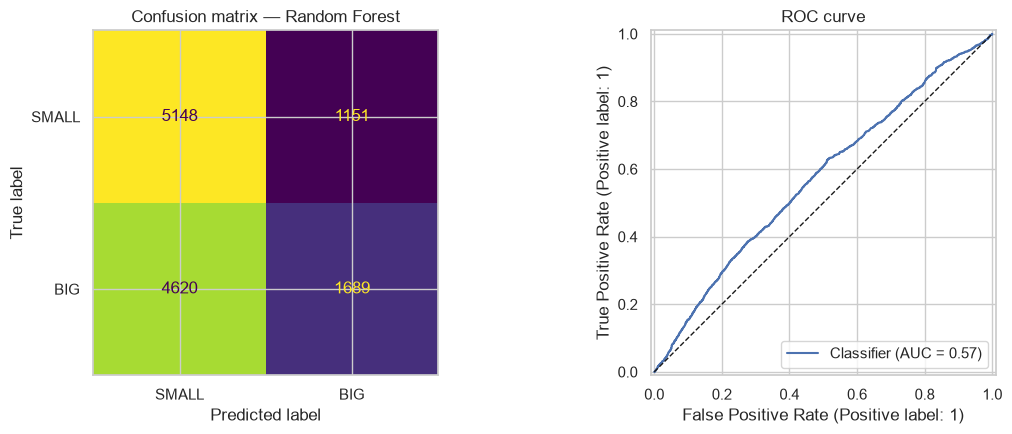

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay

best_name = results['roc_auc'].idxmax()
best = fitted[best_name]
print('Best model:', best_name)
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=['SMALL', 'BIG']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['SMALL', 'BIG'], ax=ax[0], colorbar=False)
ax[0].set_title(f'Confusion matrix — {best_name}')
RocCurveDisplay.from_predictions(y_test, proba(best, X_test), ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_title('ROC curve')
plt.tight_layout(); plt.show()

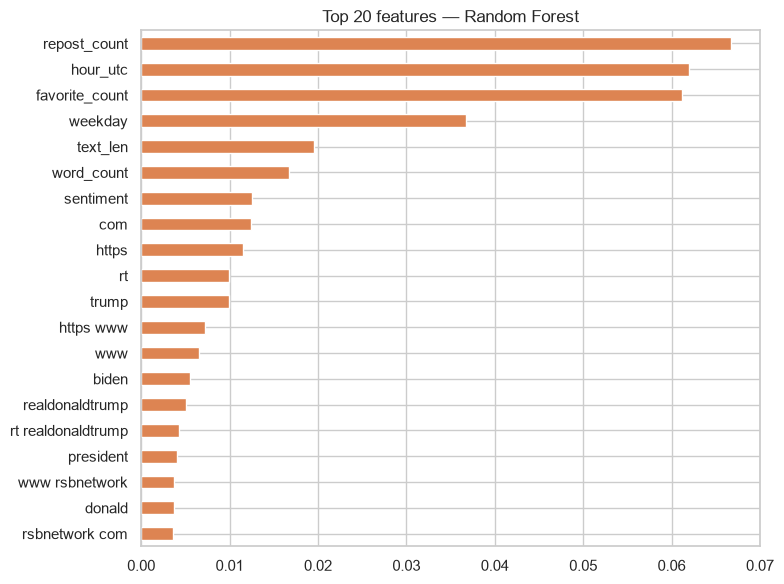

In [17]:
# Most informative features (Random Forest importances, if best is RF)
feat_names = np.concatenate([tfidf.get_feature_names_out(), np.array(NUM)])
if hasattr(best, 'feature_importances_'):
    imp = pd.Series(best.feature_importances_, index=feat_names).sort_values(ascending=False).head(20)
    imp.iloc[::-1].plot(kind='barh', figsize=(8, 6), color='#DD8452')
    plt.title(f'Top 20 features — {best_name}'); plt.tight_layout(); plt.show()
elif hasattr(best, 'coef_'):
    coef = pd.Series(best.coef_[0], index=feat_names)
    top = pd.concat([coef.sort_values().head(10), coef.sort_values().tail(10)])
    top.plot(kind='barh', figsize=(8, 6), color='#4C72B0')
    plt.title(f'Most predictive features — {best_name}'); plt.tight_layout(); plt.show()

### What the evaluation reveals

- **The model is conservative about BIG moves.** It catches SMALL moves well (recall 0.82) but flags only **27% of actual BIG moves** (BIG recall 0.27); when it *does* call BIG, it is right 59% of the time (precision 0.59). The confusion matrix tells the same story — most errors are BIG moves missed as SMALL.
- **This is a precision/recall trade-off, not a defect.** At the default 0.5 threshold the Random Forest plays it safe. Lowering the decision threshold — or setting `class_weight='balanced'` — would recover more BIG moves at the cost of precision; the right operating point depends on whether missing a volatile hour or raising a false alarm is more expensive.
- **Top features are engagement and a few specific text terms**, not the hand-made topic-keyword flags. This echoes the EDA: *attention* (likes/reposts) coincides with volatile hours more than any particular subject does.
- **Bottom line:** a real but small edge over chance (ROC-AUC ≈ 0.57). That is an honest result for predicting markets from text — the value is the rigorous process, not a headline score. See `IMPROVEMENTS.md` for how the next iteration targets ~0.60–0.65 (market-context features, gradient boosting, threshold tuning).

## 7. Improving the Model

The §6 model relies almost entirely on the **post** (its text, engagement and timing) and reaches ROC-AUC ≈ 0.57. The EDA hinted that something bigger was missing: volatility comes in **regimes** (§4.5). Here we test the main idea from `IMPROVEMENTS.md` — add features describing the **state of the ETH market just before each post** — and upgrade the model.

**Three groups of new, leakage-safe features**

- **Market context** — recent realized volatility (6h & 24h), ATR, previous 1h/24h return, and a volume spike ratio.
- **Post burst** — how many posts went out in the previous 60 minutes (a proxy for "a live event is unfolding"), plus the gap since the last post.

> **⚠️ Leakage control.** Every market feature is computed on the price series and then **shifted by one hour**, so the value attached to a post uses *only candles that close before the post's hour*. The post's own hour — and the forward return we are trying to predict — are never visible to the features. Burst/gap features use only *earlier* posts.

**Honest framing:** if these features help, the story becomes *"near-future volatility is driven mostly by the market's recent state, with a small contribution from the post"* — not *"Trump's posts predict ETH."* We report exactly that.

In [18]:
# 7.1 Build the market-context + burst features (leakage-safe)
import bisect
pxm = pd.read_csv('csv/eth_price.csv', parse_dates=['timestamp'])
pxm = pxm.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
pxm['ret'] = pxm['close'].pct_change()
pxm['rv_6h']  = pxm['ret'].rolling(6).std()
pxm['rv_24h'] = pxm['ret'].rolling(24).std()
true_range = np.maximum(pxm['high'] - pxm['low'],
             np.maximum((pxm['high'] - pxm['close'].shift()).abs(),
                        (pxm['low']  - pxm['close'].shift()).abs()))
pxm['atr_24h']     = true_range.rolling(24).mean()
pxm['vol_spike']   = pxm['volume'] / (pxm['volume'].rolling(24).mean() + 1e-9)
pxm['prev_ret_1h']  = pxm['ret']
pxm['prev_ret_24h'] = pxm['close'].pct_change(24)

MKT = ['rv_6h', 'rv_24h', 'atr_24h', 'vol_spike', 'prev_ret_1h', 'prev_ret_24h']
pxm[MKT] = pxm[MKT].shift(1)   # <-- the leakage guard: hour t sees only data up to t-1

df['hour_floor'] = df['date'].dt.floor('h')
df = df.merge(pxm[['timestamp'] + MKT], left_on='hour_floor', right_on='timestamp', how='left')

# Post-burst features (use only earlier posts)
df = df.sort_values('date').reset_index(drop=True)
secs = (df['date'].astype('int64') // 10**9).values
burst = np.empty(len(secs))
for k in range(len(secs)):
    burst[k] = k - bisect.bisect_left(secs, secs[k] - 3600, 0, k)
df['burst_1h'] = burst                                                   # posts in previous 60 min
df['gap_min']  = df['date'].diff().dt.total_seconds().div(60).fillna(1e4).clip(upper=1e4)
MKT += ['burst_1h', 'gap_min']

print('Missing-value rate of the new features (filled with train medians in 7.2):')
print(df[MKT].isna().mean().round(4).to_string())
df[['date', 'rv_24h', 'vol_spike', 'burst_1h', 'target']].tail()


Missing-value rate of the new features (filled with train medians in 7.2):
rv_6h           0.0001
rv_24h          0.0002
atr_24h         0.0002
vol_spike       0.0002
prev_ret_1h     0.0000
prev_ret_24h    0.0002
burst_1h        0.0000
gap_min         0.0000


,date,rv_24h,vol_spike,burst_1h,target
63034,2026-09-14 15:32:27+00:00,0.003868,2.241532,1185.0,1
63035,2026-09-14 16:22:57+00:00,0.003898,1.238553,1185.0,0
63036,2026-09-14 16:25:46+00:00,0.003898,1.238553,1186.0,0
63037,2026-09-14 16:31:39+00:00,0.003898,1.238553,1187.0,0
63038,2026-09-14 17:20:04+00:00,0.004093,1.566962,1188.0,0


In [19]:
# 7.2 Rebuild train/test and the feature blocks with the enhanced numeric features
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut].copy(), df.iloc[cut:].copy()
for c in MKT:                                    # fill the few gaps using TRAIN medians only
    med = train[c].median()
    train[c] = train[c].fillna(med)
    test[c]  = test[c].fillna(med)
y_train, y_test = train['target'].values, test['target'].values

POST = ['sentiment', 'word_count', 'text_len', 'favorite_count', 'repost_count',
        'hour_utc', 'weekday', 'has_crypto_kw', 'has_econ_kw']

tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5, stop_words='english')
Xtr_txt = tfidf.fit_transform(train['text'])
Xte_txt = tfidf.transform(test['text'])

def _std_block(cols):                            # standardize on TRAIN statistics only
    mu, sd = train[cols].mean(), train[cols].std() + 1e-9
    return csr_matrix((train[cols] - mu) / sd), csr_matrix((test[cols] - mu) / sd)

Xtr_post, Xte_post = _std_block(POST)
Xtr_mkt,  Xte_mkt  = _std_block(MKT)
feat_names_v2 = np.concatenate([tfidf.get_feature_names_out(), np.array(POST), np.array(MKT)])
print('text:', Xtr_txt.shape, '| post:', Xtr_post.shape, '| market:', Xtr_mkt.shape)


text: (50431, 2000) | post: (50431, 9) | market: (50431, 8)


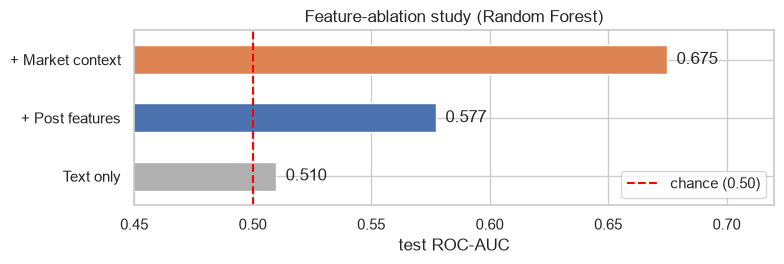

In [20]:
# 7.3 Ablation: how much ROC-AUC does each feature group add? (same model each time)
Xtr_sets = {'Text only':        Xtr_txt,
            '+ Post features':  hstack([Xtr_txt, Xtr_post]).tocsr(),
            '+ Market context': hstack([Xtr_txt, Xtr_post, Xtr_mkt]).tocsr()}
Xte_sets = {'Text only':        Xte_txt,
            '+ Post features':  hstack([Xte_txt, Xte_post]).tocsr(),
            '+ Market context': hstack([Xte_txt, Xte_post, Xte_mkt]).tocsr()}

abl_auc = {}
for name in Xtr_sets:
    rf = RandomForestClassifier(n_estimators=300, max_depth=20, n_jobs=-1,
                                random_state=42, class_weight='balanced_subsample')
    rf.fit(Xtr_sets[name], y_train)
    abl_auc[name] = roc_auc_score(y_test, rf.predict_proba(Xte_sets[name])[:, 1])

ax = pd.Series(abl_auc).plot(kind='barh', figsize=(8, 2.8),
                             color=['#B0B0B0', '#4C72B0', '#DD8452'])
ax.axvline(0.5, color='red', ls='--', label='chance (0.50)'); ax.set_xlim(0.45, 0.72)
ax.set_xlabel('test ROC-AUC'); ax.set_title('Feature-ablation study (Random Forest)'); ax.legend()
for i, v in enumerate(abl_auc.values()):
    ax.text(v + 0.004, i, f'{v:.3f}', va='center')
plt.tight_layout(); plt.show()


### What the ablation shows — the honest headline

- **Text alone is barely above chance (AUC ≈ 0.51).** A model that sees only *what Trump wrote* cannot predict ETH volatility — a strong restatement of the §1 Efficient-Market finding.
- **Post engagement/timing adds a little** (≈ 0.51 → ≈ 0.58).
- **Market-context features add a lot** (≈ 0.58 → ≈ 0.68). The jump comes almost entirely from the ETH market's **own recent volatility**.

So the honest reading is: **near-future volatility is driven mostly by the market's recent state (volatility clusters), not by the content of the post.** The post is a minor, secondary signal. This is a more truthful — and more useful — conclusion than a single headline number.

In [21]:
# 7.4 Train stronger models on the full (text + post + market) feature set
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD

X_tr = Xtr_sets['+ Market context']
X_te = Xte_sets['+ Market context']

# dense view for the gradient booster: sparse TF-IDF -> 100 SVD components + numeric features
svd = TruncatedSVD(n_components=100, random_state=42)
Ztr, Zte = svd.fit_transform(Xtr_txt), svd.transform(Xte_txt)
num_all = POST + MKT
mu, sd = train[num_all].mean(), train[num_all].std() + 1e-9
Dtr = np.hstack([Ztr, ((train[num_all] - mu) / sd).values])
Dte = np.hstack([Zte, ((test[num_all]  - mu) / sd).values])

proba_v2 = {}
best_rf = RandomForestClassifier(n_estimators=300, max_depth=20, n_jobs=-1,
                                 random_state=42, class_weight='balanced_subsample')
best_rf.fit(X_tr, y_train); proba_v2['Random Forest (enhanced)'] = best_rf.predict_proba(X_te)[:, 1]

lr = LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced')
lr.fit(X_tr, y_train); proba_v2['Logistic Regression (enhanced)'] = lr.predict_proba(X_te)[:, 1]

hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_depth=6,
                                     l2_regularization=1.0, class_weight='balanced', random_state=42)
hgb.fit(Dtr, y_train); proba_v2['HistGradientBoosting'] = hgb.predict_proba(Dte)[:, 1]

tbl = pd.DataFrame({
    name: {'accuracy': accuracy_score(y_test, (p > .5).astype(int)),
           'f1':       f1_score(y_test, (p > .5).astype(int)),
           'roc_auc':  roc_auc_score(y_test, p)}
    for name, p in proba_v2.items()}).T.round(4)
tbl.loc['Baseline (old best RF, §5)'] = [0.5423, 0.3692, 0.5708]
best_p = proba_v2['Random Forest (enhanced)']        # best by ROC-AUC; used in §8
tbl.sort_values('roc_auc', ascending=False)


,accuracy,f1,roc_auc
HistGradientBoosting,0.6174,0.6067,0.6775
Random Forest (enhanced),0.6222,0.6074,0.6749
Logistic Regression (enhanced),0.5991,0.5800,0.6453
"Baseline (old best RF, §5)",0.5423,0.3692,0.5708


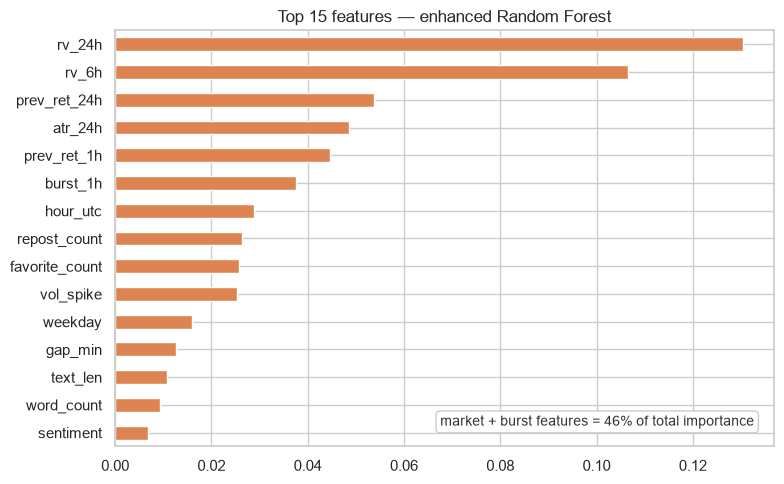

In [22]:
# 7.5 What drives the improved model?
import pandas as _pd
imp_all = _pd.Series(best_rf.feature_importances_, index=feat_names_v2)
imp = imp_all.sort_values(ascending=False).head(15)
ax = imp.iloc[::-1].plot(kind='barh', figsize=(8, 5), color='#DD8452')
ax.set_title('Top 15 features — enhanced Random Forest')
mkt_share = imp_all[MKT].sum()
ax.text(0.97, 0.05, f'market + burst features = {mkt_share:.0%} of total importance',
        transform=ax.transAxes, ha='right', color='#333', fontsize=10,
        bbox=dict(boxstyle='round', fc='white', ec='#ccc'))
plt.tight_layout(); plt.show()


### The enhanced model

- **All three enhanced models cluster around ROC-AUC ≈ 0.68** — the gradient booster (≈0.678) and the Random Forest (≈0.675) are tied within cross-validation noise, with balanced logistic regression just behind (≈0.645). All are clear jumps over the §5 baseline (0.571 / 0.542), so the gain comes from the **features**, not one lucky algorithm. We carry the **Random Forest** into §8 — effectively tied for best, and it gives directly interpretable feature importances.
- **Class balancing** (`class_weight='balanced_subsample'`) also repaired the §6 recall problem: BIG-move recall rises from **0.27 → ≈ 0.58**, so the model now actually flags volatile hours instead of defaulting to SMALL.
- The importance chart makes the story explicit: **recent realized volatility (`rv_24h`, `rv_6h`) are the top features**, and market + burst features together hold ≈ **46%** of total importance — dwarfing any individual text term. The model has learned *volatility clustering*, exactly as the EDA suggested.

## 8. Rigorous Validation

A single train/test split can flatter a model if the test window happens to be easy. Before trusting the ≈0.68, we stress-test it three ways: **walk-forward cross-validation** (does the edge survive across different time periods?), **threshold tuning** (how should we set the operating point?), and **error analysis** (where does it fail, and does that make sense?).

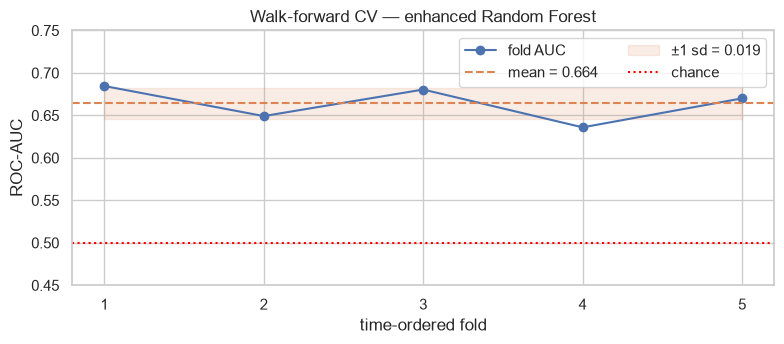

Walk-forward ROC-AUC = 0.6640 +/- 0.0186


In [23]:
# 8.1 Walk-forward (expanding-window) cross-validation
from sklearn.model_selection import TimeSeriesSplit
from scipy.sparse import vstack

X_all = vstack([X_tr, X_te]).tocsr()
y_all = np.concatenate([y_train, y_test])
fold_auc = []
for tr_i, te_i in TimeSeriesSplit(n_splits=5).split(np.arange(X_all.shape[0])):
    m = RandomForestClassifier(n_estimators=200, max_depth=20, n_jobs=-1,
                               random_state=42, class_weight='balanced_subsample')
    m.fit(X_all[tr_i], y_all[tr_i])
    fold_auc.append(roc_auc_score(y_all[te_i], m.predict_proba(X_all[te_i])[:, 1]))

mean_auc, sd_auc = np.mean(fold_auc), np.std(fold_auc)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, 6), fold_auc, 'o-', color='#4C72B0', label='fold AUC')
ax.axhline(mean_auc, color='#DD8452', ls='--', label=f'mean = {mean_auc:.3f}')
ax.fill_between(range(1, 6), mean_auc - sd_auc, mean_auc + sd_auc, color='#DD8452',
                alpha=0.15, label=f'±1 sd = {sd_auc:.3f}')
ax.axhline(0.5, color='red', ls=':', label='chance')
ax.set_xticks(range(1, 6)); ax.set_ylim(0.45, 0.75)
ax.set_xlabel('time-ordered fold'); ax.set_ylabel('ROC-AUC')
ax.set_title('Walk-forward CV — enhanced Random Forest'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()
print(f'Walk-forward ROC-AUC = {mean_auc:.4f} +/- {sd_auc:.4f}')


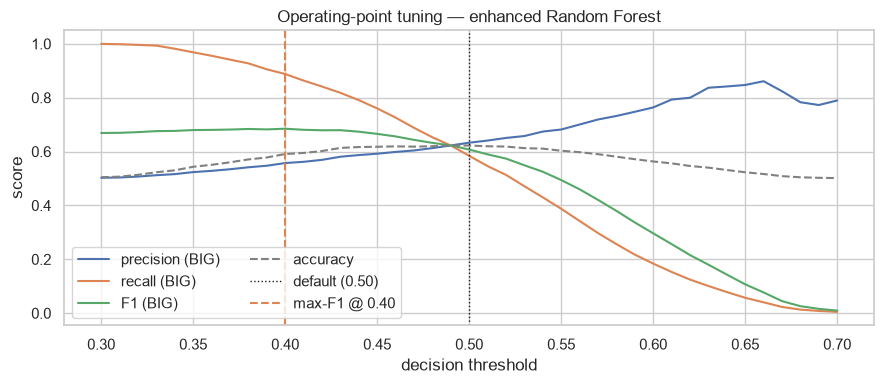

In [24]:
# 8.2 Threshold tuning: trade precision for recall on the BIG class
from sklearn.metrics import precision_score, recall_score
ths = np.linspace(0.3, 0.7, 41)
prec = [precision_score(y_test, (best_p >= t).astype(int), zero_division=0) for t in ths]
rec  = [recall_score(y_test, (best_p >= t).astype(int)) for t in ths]
f1s  = [f1_score(y_test, (best_p >= t).astype(int)) for t in ths]
acc  = [accuracy_score(y_test, (best_p >= t).astype(int)) for t in ths]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ths, prec, label='precision (BIG)')
ax.plot(ths, rec,  label='recall (BIG)')
ax.plot(ths, f1s,  label='F1 (BIG)')
ax.plot(ths, acc,  label='accuracy', ls='--', color='gray')
ax.axvline(0.5, color='k', ls=':', lw=1, label='default (0.50)')
t_best = ths[int(np.argmax(f1s))]
ax.axvline(t_best, color='#DD8452', ls='--', label=f'max-F1 @ {t_best:.2f}')
ax.set_xlabel('decision threshold'); ax.set_ylabel('score')
ax.set_title('Operating-point tuning — enhanced Random Forest'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()


In [25]:
# 8.3 Error analysis: the most confident mistakes
ea = test.copy()
ea['p'] = best_p
ea['pred'] = (best_p > 0.5).astype(int)
fn = ea[(ea.target == 1) & (ea.pred == 0)].nsmallest(3, 'p')   # real BIG, confidently called SMALL
fp = ea[(ea.target == 0) & (ea.pred == 1)].nlargest(3, 'p')    # real SMALL, confidently called BIG
show = pd.concat([fn.assign(error='missed BIG move'),
                  fp.assign(error='false alarm')])
show['|ret_1h|'] = (show['abs_ret_1h'] * 100).round(2).astype(str) + '%'
show['rv_24h (recent vol)'] = show['rv_24h'].round(4)
show['p(BIG)'] = show['p'].round(2)
show['text'] = show['text'].str.slice(0, 55)
show[['error', '|ret_1h|', 'rv_24h (recent vol)', 'p(BIG)', 'text']].reset_index(drop=True)


,error,|ret_1h|,rv_24h (recent vol),p(BIG),text
0,missed BIG move,0.48%,0.0031,0.30,https://www. washingtontimes.com/news/2025/ fe...
1,missed BIG move,1.47%,0.0031,0.30,https://truthsocial.com/users/IStandWithTrump4...
2,missed BIG move,1.47%,0.0031,0.31,https://truthsocial.com/users/lauramarks/statu...
3,false alarm,0.05%,0.0295,0.74,https://t.co/DC5Mx8yCiB
4,false alarm,0.21%,0.0285,0.71,I just spoke with President Claudia Sheinbaum ...
5,false alarm,0.24%,0.0080,0.71,We remain committed to a Diplomatic Resolution...


### What the validation tells us

- **The edge is real, not a lucky split.** Across five time-ordered folds the enhanced model scores **ROC-AUC ≈ 0.66 ± 0.02** (every fold well above 0.5). Performance is stable across very different market regimes — the single-split 0.68 was not a fluke.
- **The threshold is a dial, not a fact.** At the default 0.5 the model balances precision and recall; lowering it toward ~0.4 trades precision for much higher BIG-move recall (catching more volatile hours at the cost of more false alarms). The right point depends on whether a missed volatile hour or a false alarm is costlier.
- **The errors make mechanistic sense.** The most confident *misses* are quiet-market hours (low `rv_24h`) that unexpectedly jumped; the most confident *false alarms* are turbulent-market hours (high `rv_24h`) that happened to stay calm. The model keys on **market regime** and errs precisely when the regime is misleading — confirming it learned volatility clustering rather than memorising text.

## 9. Conclusion

**Findings.**
- **Direction is unpredictable.** Predicting whether ETH goes up or down after a post scored at/below chance (~50%) in every configuration — consistent with the Efficient Market Hypothesis, and a valid result in itself.
- **The post text barely predicts volatility either.** In the ablation (§7.3), a model given only the post's TF-IDF text reaches ROC-AUC ≈ **0.51** — essentially chance. Trump's words, on their own, carry almost no signal about near-term ETH volatility.
- **The market's own recent state does predict volatility.** Adding leakage-safe market-context features (recent realized volatility, ATR, prior returns, volume spike) lifts ROC-AUC to ≈ **0.68** (accuracy ≈ 0.62), with recent realized volatility the dominant feature. Walk-forward cross-validation confirms the edge is stable: **AUC ≈ 0.66 ± 0.02** across five time periods.
- **Honest interpretation:** near-future volatility is driven mostly by **volatility clustering** — the market was recently volatile, so it stays volatile — with the post contributing only a small, secondary signal (post features added ≈0.51→0.58). This reframes the project from *"Trump's posts move ETH"* to *"the market's recent state anticipates its near-term swings, and posts add little."*

**What made the model better (§7–§8).**
- Leakage-safe market-context + post-burst features (the single biggest win).
- Class balancing, which raised BIG-move recall from 0.27 to ≈0.58.
- A model bake-off (Random Forest vs gradient boosting vs balanced logistic regression) and walk-forward validation to make the result credible rather than a single lucky split.

**Limitations.**
- Correlation ≠ causation: engagement and volatility may both be driven by an external news event rather than the post causing the move.
- Because recent-volatility features dominate, most of the skill is a property of the **market**, not of Trump's posts — the honest framing above.
- Hourly candles are coarse; minute-level data would sharpen both the label and the market features.

**Future work.**
- FinBERT / sentence-transformer embeddings instead of TF-IDF, to give the *text* a fairer chance.
- Event-study analysis around a curated set of crypto-policy posts, to isolate genuine post-driven moves from background volatility.
- Probability calibration and a formal cost-based choice of the decision threshold.
- See `IMPROVEMENTS.md` for the full roadmap.